In [2]:
!nvidia-smi

Fri Jul 17 08:20:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   60C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
!unzip /content/roboflow_paint_defects.zip

Archive:  /content/roboflow_paint_defects.zip
   creating: roboflow_paint_defects/
  inflating: roboflow_paint_defects/README.dataset.txt  
  inflating: roboflow_paint_defects/README.roboflow.txt  
   creating: roboflow_paint_defects/test/
  inflating: roboflow_paint_defects/test/blur_126_jpg.rf.f10a92485a1737691cb618a3d01f8747.jpg  
  inflating: roboflow_paint_defects/test/blur_134_jpg.rf.2d0c755ccaa7e980e57fe53601379c7f.jpg  
  inflating: roboflow_paint_defects/test/blur_168_jpg.rf.87fc1701ca55de6bd7363333b05948a8.jpg  
  inflating: roboflow_paint_defects/test/blur_176_jpg.rf.f1711c8e63d0788e714d22b57e62fae0.jpg  
  inflating: roboflow_paint_defects/test/blur_186_jpg.rf.d373b87434c33b180874fc9783ca2f63.jpg  
  inflating: roboflow_paint_defects/test/blur_200_jpg.rf.814ffca9dbf0217532998cf5b17bc3c4.jpg  
  inflating: roboflow_paint_defects/test/blur_21_jpg.rf.0ac9c152664cb80a6477b99a7bfad4d4.jpg  
  inflating: roboflow_paint_defects/test/blur_224_jpg.rf.635cdd243ed7159c2fcb62f57027130a

# paint_defects_multiclass

In [54]:
import os
import pandas as pd
import shutil
from collections import Counter

# --- CONFIGURATION DES CHEMINS ---
EXTRACT_DIR = '/content/roboflow_paint_defects'
OUTPUT_DIR  = '/content/roboflow_paint_defects_multiclass'

if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)

# --- 1. EXTRACTION DYNAMIQUE DES NOMS DE CATÉGORIES ---
# On lit le fichier _classes.csv du dossier train pour récupérer les en-têtes
sample_csv_path = os.path.join(EXTRACT_DIR, 'test', '_classes.csv')
if not os.path.exists(sample_csv_path):
    # Sécurité si le fichier est dans train au lieu de test
    sample_csv_path = os.path.join(EXTRACT_DIR, 'train', '_classes.csv')

df_sample = pd.read_csv(sample_csv_path)

# Les colonnes après 'filename' (index 0) représentent nos CATEGORY_NAMES
# Exemple de colonnes générées par Roboflow : ['filename', 'BLISTERING', 'BUBBLES', 'FISHEYE', ...]
CATEGORY_NAMES = [col.strip() for col in df_sample.columns if col.lower() != 'filename']
print("📋 Catégories détectées dynamiquement :", CATEGORY_NAMES)

# --- 2. TRAITEMENT ET RESTRUCTURATION PAR SPLIT ---
for split in ['train', 'valid', 'test']:
    split_folder = os.path.join(EXTRACT_DIR, split)
    csv_path = os.path.join(split_folder, '_classes.csv')

    if not os.path.exists(csv_path):
        print(f"⚠️ Aucun fichier _classes.csv trouvé pour le split : {split} (Ignoré)")
        continue

    # Lecture du fichier CSV du split courant
    df = pd.read_csv(csv_path)
    # Nettoyage des espaces éventuels dans les noms de colonnes
    df.columns = [col.strip() for col in df.columns]

    # Uniformisation de 'valid' en 'val' pour vos futurs pipelines de code
    output_split = 'val' if split == 'valid' else split

    # Création des répertoires pour chaque classe de défaut détectée
    for cls_name in CATEGORY_NAMES:
        os.makedirs(f'{OUTPUT_DIR}/{output_split}/{cls_name}', exist_ok=True)

    class_counts = Counter()

    # Parcours de chaque ligne du fichier CSV
    for _, row in df.iterrows():
        filename = row['filename'].strip()
        src_path = os.path.join(split_folder, filename)

        if not os.path.exists(src_path):
            continue  # Ignore si l'image physique est manquante

        # Trouver la ou les classes qui ont la valeur 1 pour cette ligne
        active_classes = [cls for cls in CATEGORY_NAMES if row[cls] == 1]

        if active_classes:
            # En cas de multi-labellisation sur un patch, on prend la première classe listée
            dominant_label = active_classes[0]

            dst_path = os.path.join(OUTPUT_DIR, output_split, dominant_label, filename)
            shutil.copy(src_path, dst_path)
            class_counts[dominant_label] += 1
        else:
            # Si aucune classe n'est active (toutes à 0), on peut classer dans un dossier "Unclassified" ou "Normal"
            os.makedirs(f'{OUTPUT_DIR}/{output_split}/NORMAL', exist_ok=True)
            dst_path = os.path.join(OUTPUT_DIR, output_split, 'NORMAL', filename)
            shutil.copy(src_path, dst_path)
            class_counts['NORMAL'] += 1

    # Affichage de la distribution finale par classe
    print(f"\n[{output_split.upper()}] Distribution :")
    for cls, cnt in sorted(class_counts.items(), key=lambda x: -x[1]):
        print(f"   {cls:<20}: {cnt}")
    print(f"   {'TOTAL':<20}: {sum(class_counts.values())}")


📋 Catégories détectées dynamiquement : ['BLISTERING', 'BUBBLES', 'FISHEYE', 'ORANGEPEEL', 'SAG', 'SCRATCH', 'SOLVENTPOP']

[TRAIN] Distribution :
   ORANGEPEEL          : 378
   SCRATCH             : 332
   SAG                 : 307
   SOLVENTPOP          : 207
   BLISTERING          : 121
   FISHEYE             : 47
   BUBBLES             : 30
   NORMAL              : 2
   TOTAL               : 1424

[VAL] Distribution :
   ORANGEPEEL          : 78
   SCRATCH             : 51
   BLISTERING          : 19
   FISHEYE             : 7
   SAG                 : 7
   SOLVENTPOP          : 4
   BUBBLES             : 2
   TOTAL               : 168

[TEST] Distribution :
   SCRATCH             : 44
   BLISTERING          : 16
   ORANGEPEEL          : 11
   FISHEYE             : 6
   BUBBLES             : 3
   SAG                 : 2
   SOLVENTPOP          : 1
   TOTAL               : 83


In [91]:
#Return all the subfiles with 7 classes, where each subfile has the same number of classesimport shutil
import shutil
# Remove the tiny 8th class from train to match val and test
normal_train_dir = '/content/roboflow_paint_defects_multiclass/train/NORMAL'
if os.path.exists(normal_train_dir):
    shutil.rmtree(normal_train_dir)
    print("🧹 Successfully removed the 2 'NORMAL' images. You now have 7 clean classes matching across all splits!")


In [92]:
# re-size all the images to this
IMAGE_SIZE = [384, 384]

In [94]:
#if the datasets in black and white (1 channel) we indicate that we work with 3 channels
size = [384, 384] + [3]
size

[384, 384, 3]

In [95]:
train_path = '/content/roboflow_paint_defects_multiclass/train'
valid_path = '/content/roboflow_paint_defects_multiclass/val'

In [125]:
import tensorflow as tf
from tensorflow.keras.applications.efficientnet import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator,load_img
import numpy as np
from glob import glob
from tensorflow.keras.models import Sequential
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Lambda, Dense, Flatten
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout

In [126]:
EfficientNetB0 = EfficientNetB0(input_shape=IMAGE_SIZE + [3],  weights='imagenet', include_top=False)

In [127]:
for layer in EfficientNetB0.layers:
    layer.trainable = False

In [128]:
for layer in EfficientNetB0.layers:
  print(layer.trainable)

False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
Fals

In [129]:
for layer in EfficientNetB0.layers:
  print(layer.name,layer.trainable)

input_layer_9 False
rescaling_14 False
normalization_7 False
rescaling_15 False
stem_conv_pad False
stem_conv False
stem_bn False
stem_activation False
block1a_dwconv False
block1a_bn False
block1a_activation False
block1a_se_squeeze False
block1a_se_reshape False
block1a_se_reduce False
block1a_se_expand False
block1a_se_excite False
block1a_project_conv False
block1a_project_bn False
block2a_expand_conv False
block2a_expand_bn False
block2a_expand_activation False
block2a_dwconv_pad False
block2a_dwconv False
block2a_bn False
block2a_activation False
block2a_se_squeeze False
block2a_se_reshape False
block2a_se_reduce False
block2a_se_expand False
block2a_se_excite False
block2a_project_conv False
block2a_project_bn False
block2b_expand_conv False
block2b_expand_bn False
block2b_expand_activation False
block2b_dwconv False
block2b_bn False
block2b_activation False
block2b_se_squeeze False
block2b_se_reshape False
block2b_se_reduce False
block2b_se_expand False
block2b_se_excite False


In [130]:
EfficientNetB0.summary()

Model: "efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 384, 384,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_14        │ (None, 384, 384,  │          0 │ input_layer_9[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_7     │ (None, 384, 384,  │          7 │ rescaling_14[0][… │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_15        │ (None, 384, 384,  │          0 │ normalization_7[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 385, 385,  │          0 │ rescaling_15[0][… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 192, 192,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 192, 192,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 192, 192,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 192, 192,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 192, 192,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 192, 192,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 192, 192,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 192, 192,  │        512 │ block1a_se_excit

 Total params: 4,049,571 (15.45 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 4,049,571 (15.45 MB)

In [131]:
folders = glob('/content/roboflow_paint_defects_multiclass/train/*')
folders

['/content/roboflow_paint_defects_multiclass/train/FISHEYE',
 '/content/roboflow_paint_defects_multiclass/train/BLISTERING',
 '/content/roboflow_paint_defects_multiclass/train/ORANGEPEEL',
 '/content/roboflow_paint_defects_multiclass/train/SAG',
 '/content/roboflow_paint_defects_multiclass/train/SCRATCH',
 '/content/roboflow_paint_defects_multiclass/train/BUBBLES',
 '/content/roboflow_paint_defects_multiclass/train/SOLVENTPOP']

In [132]:
num_of_class = len(folders)
num_of_class

7

In [133]:
model = Sequential()
model.add(EfficientNetB0)
model.add(GlobalAveragePooling2D())
model.add(Dropout(0.4))
model.add(Dense(256,activation='relu'))
model.add(Dense(num_of_class,activation='softmax'))

In [134]:
# view the structure of the model
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 12, 12, 1280)   │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,379,306 (16.71 MB)

 Trainable params: 329,735 (1.26 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [135]:
model.compile(
  loss='categorical_crossentropy',
  optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
  metrics=['accuracy']
)

# data augmentation

In [136]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [137]:
train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)

val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

In [138]:
training_set = train_datagen.flow_from_directory(train_path,
                                                 target_size = (384, 384),
                                                 batch_size = 32,
                                                 class_mode = 'categorical',
                                                 shuffle=True)

Found 1422 images belonging to 7 classes.


In [139]:
validation_set = val_datagen.flow_from_directory(valid_path,
                                            target_size = (384, 384),
                                            batch_size = 32,
                                            class_mode = 'categorical',
                                            shuffle=False)

Found 168 images belonging to 7 classes.


In [141]:
r = model.fit(
  training_set,
  validation_data=validation_set,
  epochs=10,
  steps_per_epoch=len(training_set),
  validation_steps=len(validation_set)
)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.9606 - loss: 0.1221 - val_accuracy: 0.9762 - val_loss: 0.0807
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.9550 - loss: 0.1249 - val_accuracy: 0.9643 - val_loss: 0.0976
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.9705 - loss: 0.0964 - val_accuracy: 0.9702 - val_loss: 0.0962
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.9719 - loss: 0.0924 - val_accuracy: 0.9583 - val_loss: 0.1517
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.9747 - loss: 0.0799 - val_accuracy: 0.9702 - val_loss: 0.0747
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.9705 - loss: 0.0856 - val_accuracy: 0.9762 - val_loss: 0.0739
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step - accuracy: 0.9796 - loss: 0.0624 - val_accuracy: 0.9881 - val_loss: 0.0483
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.9747 - loss: 0.0686 - val_accuracy: 0.9583 - val_loss:

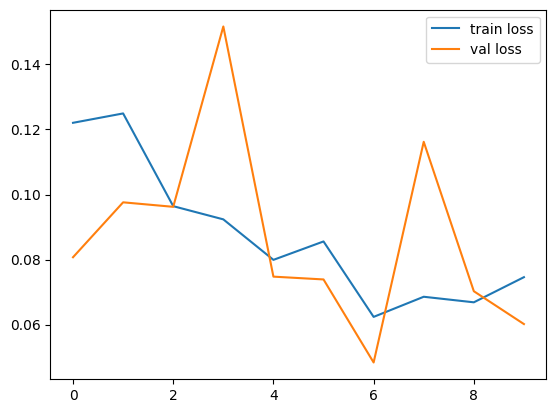

<Figure size 640x480 with 0 Axes>

In [142]:
import matplotlib.pyplot as plt
# plot the loss
plt.plot(r.history['loss'], label='train loss')
plt.plot(r.history['val_loss'], label='val loss')
plt.legend()
plt.show()
plt.savefig('LossVal_loss')

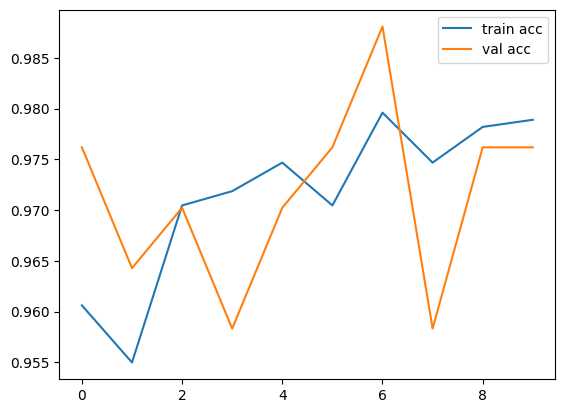

<Figure size 640x480 with 0 Axes>

In [143]:
# plot the accuracy
plt.plot(r.history['accuracy'], label='train acc')
plt.plot(r.history['val_accuracy'], label='val acc')
plt.legend()
plt.show()
plt.savefig('AccVal_acc')

In [144]:
model.evaluate(validation_set)

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - accuracy: 0.9762 - loss: 0.0602


[0.06016138195991516, 0.976190447807312]

In [187]:
from tensorflow.keras.models import load_model

model.save('model_EfficientNetB0.keras')
print("Model saved as 'model_EfficientNetB0.keras'")

Model saved as 'model_EfficientNetB0.keras'


In [188]:
model = load_model("model_EfficientNetB0.keras")

# we're going to test some test images

In [189]:
from tensorflow.keras.preprocessing import image

In [203]:
img = "/content/roboflow_paint_defects_multiclass/test/SOLVENTPOP/solvent_pop_rot270_3878bfbd-482c-4e19-98e2-d15352c2ecf3_jpg.rf.369e77ee816abb97d05a086154f6d1b8.jpg"

In [204]:
img=image.load_img(img,target_size=(384,384))

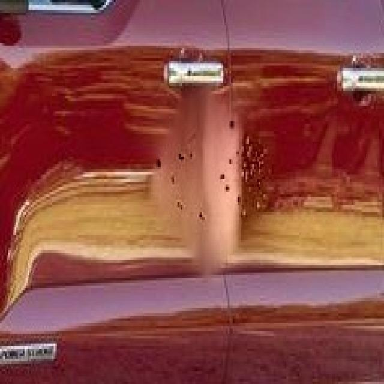

In [205]:
img

In [206]:
x=image.img_to_array(img)
x

array([[[ 52.,  51.,  46.],
        [ 52.,  51.,  46.],
        [ 53.,  53.,  45.],
        ...,
        [114.,  75., 106.],
        [115.,  76., 107.],
        [121.,  82., 113.]],

       [[ 52.,  49.,  44.],
        [ 52.,  49.,  44.],
        [ 52.,  49.,  42.],
        ...,
        [114.,  75., 106.],
        [114.,  75., 106.],
        [118.,  79., 110.]],

       [[ 69.,  64.,  60.],
        [ 69.,  64.,  60.],
        [ 67.,  62.,  56.],
        ...,
        [120.,  81., 112.],
        [119.,  80., 111.],
        [119.,  80., 111.]],

       ...,

       [[ 91.,  21.,  31.],
        [ 91.,  21.,  31.],
        [ 93.,  23.,  33.],
        ...,
        [121.,  69.,  73.],
        [125.,  73.,  77.],
        [126.,  74.,  78.]],

       [[ 85.,  15.,  25.],
        [ 86.,  16.,  26.],
        [ 89.,  19.,  29.],
        ...,
        [159., 107., 111.],
        [157., 105., 109.],
        [155., 103., 107.]],

       [[ 85.,  15.,  25.],
        [ 87.,  17.,  27.],
        [ 90.,  

In [207]:
x.shape

(384, 384, 3)

In [208]:
import numpy as np
x=np.expand_dims(x,axis=0)
img_data=preprocess_input(x)

In [209]:
output = model.predict(img_data)
output

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


array([[5.400790e-06, 6.484583e-06, 4.507744e-07, 1.977035e-02,
        1.310369e-05, 7.846899e-06, 9.801964e-01]], dtype=float32)

In [210]:
result = np.argmax(output, axis=1)
result

array([6])

In [211]:
predicted_class_index = result[0]
prediction = CATEGORY_NAMES[predicted_class_index]
print(f"The predicted class is: {prediction}")

The predicted class is: SOLVENTPOP


# confusion matrix


CLASSIFICATION REPORT
              precision    recall  f1-score   support

  BLISTERING       1.00      0.81      0.90        16
     BUBBLES       1.00      1.00      1.00         3
     FISHEYE       1.00      1.00      1.00         6
  ORANGEPEEL       0.91      0.91      0.91        11
         SAG       1.00      1.00      1.00         2
     SCRATCH       1.00      1.00      1.00        44
  SOLVENTPOP       0.25      1.00      0.40         1

    accuracy                           0.95        83
   macro avg       0.88      0.96      0.89        83
weighted avg       0.98      0.95      0.96        83



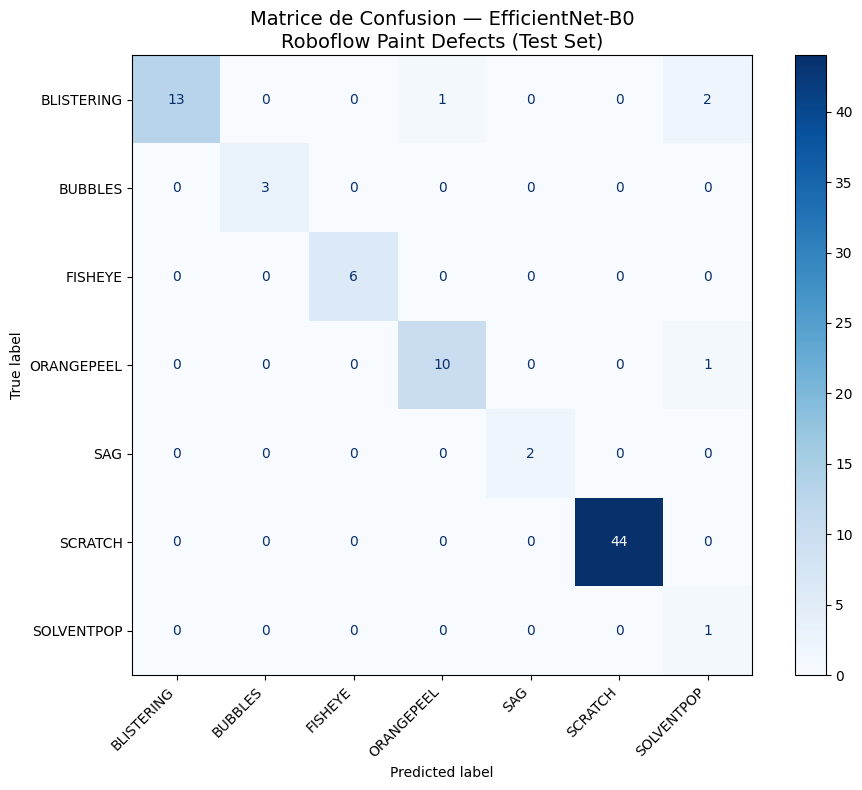

✅ Matrice de confusion sauvegardée


In [213]:
# ============================================================
# 2. CLASSIFICATION REPORT
# ============================================================
print(f"\n{'='*60}")
print("CLASSIFICATION REPORT")
print(f"{'='*60}")
print(classification_report(y_true, y_pred, target_names=class_names))

# ============================================================
# 3. MATRICE DE CONFUSION
# ============================================================
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', colorbar=True)
plt.title('Matrice de Confusion — EfficientNet-B0\nRoboflow Paint Defects (Test Set)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('confusion_matrix_efficientnetb0.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Matrice de confusion sauvegardée")

In [215]:
# ============================================================
# 5. ANALYSE DES ERREURS
# ============================================================
errors = np.where(y_true != y_pred)[0]

print(f"\n{'='*60}")
print(f"ANALYSE DES ERREURS ({len(errors)} erreurs sur {total} images)")
print(f"{'='*60}")

if len(errors) > 0:
    print(f"\n{'Image':<60} {'Vraie Classe':<15} {'Prédiction':<15} {'Confiance':<10}")
    print("-" * 100)

    for idx in errors:
        img_name = os.path.basename(image_paths[idx])
        true_class = index_to_class[y_true[idx]]
        pred_class = index_to_class[y_pred[idx]]
        conf = y_conf[idx] * 100

        print(f"{img_name:<60} {true_class:<15} {pred_class:<15} {conf:<10.1f}%")
else:
    print("🎉 Aucune erreur ! Le modèle est parfait sur le jeu de test.")


ANALYSE DES ERREURS (4 erreurs sur 83 images)

Image                                                        Vraie Classe    Prédiction      Confiance 
----------------------------------------------------------------------------------------------------
blur_200_jpg.rf.814ffca9dbf0217532998cf5b17bc3c4.jpg         BLISTERING      ORANGEPEEL      68.8      %
orig_56_jpg.rf.59a65f06394d4d829c723e51145bf0f1.jpg          BLISTERING      SOLVENTPOP      57.6      %
orig_152_jpg.rf.04b181731cfd66d6cd3303f3e718e7fd.jpg         BLISTERING      SOLVENTPOP      96.0      %
rotated_316_jpg.rf.83a86b5a5330f31c316d9c2f2f239b4f.jpg      ORANGEPEEL      SOLVENTPOP      58.8      %
